# Experiment 16: LSTM and RNN Performance Comparison

A food-delivery platform forecasts daily orders with weekly and seasonal patterns. We simulate two years of daily order counts and compare SimpleRNN and LSTM models with the same hidden size and 30-day input window.

**Tools:** TensorFlow, Keras, NumPy, Pandas, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Prepare 30-day look-back sequences.  2. Train SimpleRNN and LSTM with equal units.  3. Compare training loss, validation loss and training time.  4. Compute MAE, RMSE and MAPE.  5. Plot forecasts and summarise the metrics in a DataFrame.

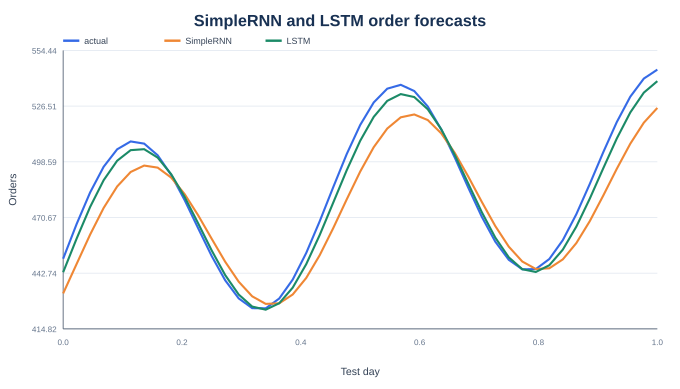

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

tf.keras.utils.set_random_seed(16)
rng=np.random.default_rng(16)
t=np.arange(730)
orders=450+60*np.sin(2*np.pi*t/7)+.08*t+35*np.sin(2*np.pi*t/365)+rng.normal(0,12,len(t))
scaler=MinMaxScaler(); s=scaler.fit_transform(orders[:,None]).ravel()
window=30
X=np.array([s[i-window:i] for i in range(window,len(s))],dtype="float32")[...,None]
y=s[window:].astype("float32")
split=int(.8*len(X));Xtr,Xte=X[:split],X[split:];ytr,yte=y[:split],y[split:]
models={
 "SimpleRNN":tf.keras.layers.SimpleRNN(24),
 "LSTM":tf.keras.layers.LSTM(24)
}
rows=[]; forecasts={}
for name,cell in models.items():
    m=tf.keras.Sequential([tf.keras.layers.Input((window,1)),cell,tf.keras.layers.Dense(1)])
    m.compile(optimizer="adam",loss="mse")
    start=time.perf_counter()
    h=m.fit(Xtr,ytr,validation_split=.1,epochs=15,batch_size=32,verbose=0)
    seconds=time.perf_counter()-start
    pred_scaled=m.predict(Xte,verbose=0).ravel()
    actual=scaler.inverse_transform(yte[:,None]).ravel()
    pred=scaler.inverse_transform(pred_scaled[:,None]).ravel()
    forecasts[name]=pred
    rows.append({"model":name,"MAE":mean_absolute_error(actual,pred),
                 "RMSE":mean_squared_error(actual,pred)**.5,
                 "MAPE (%)":np.mean(np.abs((actual-pred)/actual))*100,
                 "seconds":seconds,"final train loss":h.history["loss"][-1],
                 "final val loss":h.history["val_loss"][-1]})
print(pd.DataFrame(rows).round(3).to_string(index=False))
plt.figure(figsize=(10,4));plt.plot(actual,label="actual",lw=2)
for name,pred in forecasts.items():plt.plot(pred,label=name,alpha=.8)
plt.xlabel("Test day");plt.ylabel("Daily orders");plt.title("Order-volume forecast comparison")
plt.legend();plt.tight_layout();plt.show()